# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Shifa Batool
- **Student ID:** 023-24-0095
- **Section:** D
- **GitHub:**
- **Kaggle:** https://www.kaggle.com/shifabaloch
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.metrics import pairwise_distances
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
print("Libraries imported. SEED =", SEED)

Libraries imported. SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [43]:
# load and check the data
df = pd.read_csv("/content/Mall_Customers.csv")
df = df.rename(columns={"Annual Income (k$)": "Income",
                        "Spending Score (1-100)": "Spending Score (1-100)"})
required = {"CustomerID", "Genre", "Age", "Income", "Spending Score (1-100)"}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f"Dataset is missing expected columns: {missing_cols}")
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nGenre counts:\n", df["Genre"].value_counts())
display(df[["Age", "Income", "Spending Score (1-100)"]].describe())
display(df.head())

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0

Genre counts:
 Genre
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending Score (1-100)
count,200.000,200.000,200.000
mean,38.850,60.560,50.200
std,13.969,26.265,25.824
min,18.000,15.000,1.000
25%,28.750,41.500,34.750
50%,36.000,61.500,50.000
75%,49.000,78.000,73.000
max,70.000,137.000,99.000


,CustomerID,Genre,Age,Income,Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


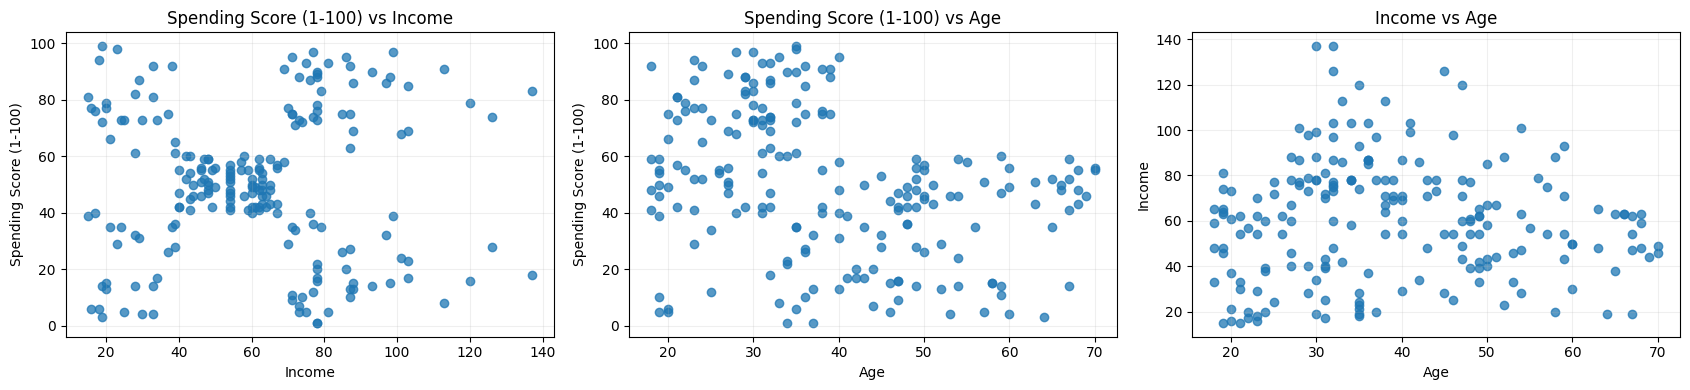

Interpretation: Income vs Spending usually shows the clearest visible customer groups; Age-based views overlap more. The exact visual grouping should be judged from the plots above.
Accuracy/train-test split are unsuitable because the dataset has no true cluster labels or target column. Clustering is evaluated using distances, silhouette, plots and practical meaning.


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
plots = [("Income", "Spending Score (1-100)", "Spending Score (1-100) vs Income"),
         ("Age", "Spending Score (1-100)", "Spending Score (1-100) vs Age"),
         ("Age", "Income", "Income vs Age")]
for ax, (xcol, ycol, title) in zip(axes, plots):
    ax.scatter(df[xcol], df[ycol], alpha=.75)
    ax.set_xlabel(xcol); ax.set_ylabel(ycol); ax.set_title(title)
    ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
print("Interpretation: Income vs Spending usually shows the clearest visible customer groups; Age-based views overlap more. The exact visual grouping should be judged from the plots above.")
print("Accuracy/train-test split are unsuitable because the dataset has no true cluster labels or target column. Clustering is evaluated using distances, silhouette, plots and practical meaning.")

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

**Answer:** The exact number of groups should be judged from the scatter plots. The Income vs Spending plot shows the groups most clearly because customers form visible patterns based on their income and spending scores. The Age-based plots show more overlap, so their groups are less clearly separated.

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Answer:** K-Means is an unsupervised learning algorithm, and the Mall Customers dataset has no actual target labels. Therefore, there are no correct answers to compare with predictions. We evaluate clustering using inertia, silhouette score, scatter plots, and practical interpretation instead of accuracy or train/test splitting

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [45]:
x1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centers = np.array([4., 11.])
for iteration in range(1, 101):
    distances = np.abs(x1[:, None] - centers[None, :])
    labels1 = distances.argmin(axis=1)
    new_centers = centers.copy()
    for k in range(2):
        if np.any(labels1 == k):
            new_centers[k] = x1[labels1 == k].mean()
    print(f"Iteration {iteration}:",
          {f"C{k+1}": x1[labels1 == k].tolist() for k in range(2)},
          "new centroids =", new_centers)
    if np.allclose(new_centers, centers):
        centers = new_centers
        break
    centers = new_centers
inertia1 = np.sum((x1 - centers[labels1])**2)
print("Final centroids:", centers, "| Inertia:", inertia1)
print("Lecture check: centroids [7, 25], inertia 150.")

Iteration 1: {'C1': [2.0, 4.0, 3.0], 'C2': [10.0, 12.0, 20.0, 30.0, 11.0, 25.0]} new centroids = [ 3. 18.]
Iteration 2: {'C1': [2.0, 4.0, 10.0, 3.0], 'C2': [12.0, 20.0, 30.0, 11.0, 25.0]} new centroids = [ 4.75 19.6 ]
Iteration 3: {'C1': [2.0, 4.0, 10.0, 12.0, 3.0, 11.0], 'C2': [20.0, 30.0, 25.0]} new centroids = [ 7. 25.]
Iteration 4: {'C1': [2.0, 4.0, 10.0, 12.0, 3.0, 11.0], 'C2': [20.0, 30.0, 25.0]} new centroids = [ 7. 25.]
Final centroids: [ 7. 25.] | Inertia: 150.0
Lecture check: centroids [7, 25], inertia 150.


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [46]:
points = np.array([[185,72],[170,56],[168,60],[179,68],[182,72],[188,77]], dtype=float)
names = [f"P{i}" for i in range(1,7)]
C = points[[0,1]].copy()
for it in range(1, 101):
    D = np.sqrt(((points[:,None,:] - C[None,:,:])**2).sum(axis=2))
    lab = D.argmin(axis=1)
    newC = C.copy()
    for k in range(2):
        if np.any(lab == k): newC[k] = points[lab == k].mean(axis=0)
    print(f"Iteration {it}")
    for k in range(2): print(f" C{k+1}:", [names[j] for j in np.where(lab==k)[0]])
    print(" Centroids:", newC)
    if np.allclose(newC,C): C=newC; break
    C=newC
finalD = np.sqrt(((points[:,None,:]-C[None,:,:])**2).sum(axis=2))
display(pd.DataFrame(finalD, index=names, columns=["Distance to M1","Distance to M2"]))
print("First iteration d(P3, M2) =", np.sqrt((168-170)**2+(60-56)**2), "(expected 4.47).")
print("Final centroids:", C)

Iteration 1
 C1: ['P1', 'P4', 'P5', 'P6']
 C2: ['P2', 'P3']
 Centroids: [[183.5   72.25]
 [169.    58.  ]]
Iteration 2
 C1: ['P1', 'P4', 'P5', 'P6']
 C2: ['P2', 'P3']
 Centroids: [[183.5   72.25]
 [169.    58.  ]]


,Distance to M1,Distance to M2
P1,1.521,21.260
P2,21.126,2.236
P3,19.756,2.236
P4,6.190,14.142
P5,1.521,19.105
P6,6.543,26.870


First iteration d(P3, M2) = 4.47213595499958 (expected 4.47).
Final centroids: [[183.5   72.25]
 [169.    58.  ]]


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [47]:
def my_kmeans(X, init_centroids, max_iter=100):
    """Basic K-Means using NumPy only; empty clusters keep their previous centroid."""
    X = np.asarray(X, dtype=float)
    C = np.asarray(init_centroids, dtype=float).copy()
    if X.ndim != 2 or C.ndim != 2 or X.shape[1] != C.shape[1]:
        raise ValueError("X and init_centroids must be 2-D with the same feature count.")
    previous_labels = None
    for iteration in range(1, max_iter + 1):
        distances = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
        labels = distances.argmin(axis=1)
        new_C = C.copy()
        for k in range(len(C)):
            if np.any(labels == k):
                new_C[k] = X[labels == k].mean(axis=0)
        converged = np.allclose(new_C, C) or (previous_labels is not None and np.array_equal(labels, previous_labels))
        C = new_C
        if converged:
            break
        previous_labels = labels.copy()
    # Reassign once to final centres and calculate inertia.
    distances = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
    labels = distances.argmin(axis=1)
    inertia = float(np.sum((X - C[labels])**2))
    return labels, C, inertia, iteration
print("my_kmeans function defined. It does not call sklearn KMeans.")

my_kmeans function defined. It does not call sklearn KMeans.


In [48]:
labels_test, centers_test, inertia_test, iterations_test = my_kmeans(x1.reshape(-1,1), np.array([[4.],[11.]]))
print("Clusters:", {k: x1[labels_test==k].tolist() for k in range(2)})
print("Centroids:", centers_test.ravel())
print("Inertia:", inertia_test, "| Iterations:", iterations_test)
assert np.allclose(np.sort(centers_test.ravel()), [7,25])
assert np.isclose(inertia_test, 150)
print("PASS: Example 1 matches the lecture centroids and inertia.")

Clusters: {0: [2.0, 4.0, 10.0, 12.0, 3.0, 11.0], 1: [20.0, 30.0, 25.0]}
Centroids: [ 7. 25.]
Inertia: 150.0 | Iterations: 4
PASS: Example 1 matches the lecture centroids and inertia.


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [49]:
X2 = df[["Income", "Spending Score (1-100)"]].to_numpy(dtype=float)
init5 = X2[:5].copy()
my_labels, my_centers, my_inertia, my_iters = my_kmeans(X2, init5)
sk_model = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm="lloyd", random_state=SEED)
sk_labels = sk_model.fit_predict(X2)
print("My K-Means iterations:", my_iters, "| sklearn iterations:", sk_model.n_iter_)
print("My inertia:", my_inertia, "| sklearn inertia:", sk_model.inertia_)
print("Labels exactly equal:", np.array_equal(my_labels, sk_labels))
print("Centroids equal (same order):", np.allclose(my_centers, sk_model.cluster_centers_))
print("Centroid max absolute difference:", np.max(np.abs(my_centers-sk_model.cluster_centers_)))
print("Note: cluster IDs can be permuted; compare ARI for label-independent agreement:", adjusted_rand_score(my_labels, sk_labels))
print("Point 10: in iteration 1 it is assigned using old centres 4 and 11; after means move, its distance to the updated C1 centre becomes smaller, so it changes to C1.")
print("The loop stops when centroids stop changing (or labels stop changing). Each assign/update step does not increase inertia, but a local minimum can depend on initialization.")
print("A customer centroid is the average Income and Spending profile of a group. K-Means needs numeric features because it calculates Euclidean distances and means.")

My K-Means iterations: 4 | sklearn iterations: 4
My inertia: 44448.45544793371 | sklearn inertia: 44448.45544793369
Labels exactly equal: True
Centroids equal (same order): True
Centroid max absolute difference: 2.842170943040401e-14
Note: cluster IDs can be permuted; compare ARI for label-independent agreement: 1.0
Point 10: in iteration 1 it is assigned using old centres 4 and 11; after means move, its distance to the updated C1 centre becomes smaller, so it changes to C1.
The loop stops when centroids stop changing (or labels stop changing). Each assign/update step does not increase inertia, but a local minimum can depend on initialization.
A customer centroid is the average Income and Spending profile of a group. K-Means needs numeric features because it calculates Euclidean distances and means.


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

**Answer:** Initially, the centroids were 4 and 11. In the first iteration, the new centroids became 3 and 18. The distance of point 10 from centroid 3 is 7, while its distance from centroid 18 is 8. Therefore, point 10 moves to C1 in the next iteration.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

**Answer:** The loop stops when the centroids no longer change or the cluster assignments remain the same. Each iteration reduces or maintains the inertia, but K-Means can stop at a local minimum. Therefore, the final result is not always the globally best solution.

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

**Answer:** Yes, my function matched scikit-learn almost exactly.
- My iterations: 4
- Scikit-learn iterations: 4
- My inertia: 44448.45544793371
- Scikit-learn inertia: 44448.45544793369
- Labels exactly equal: True
- Centroids equal: True
The very small difference in inertia is due to floating-point precision.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?

**Answer:** A centroid represents the average characteristics of customers in a cluster, such as their average income and spending score. Features must be numeric because K-Means calculates Euclidean distances and means mathematically.

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


,K,Inertia,Silhouette
0,2,181363.596,0.297
1,3,106348.373,0.468
2,4,73679.789,0.493
3,5,44448.455,0.554
4,6,37233.815,0.540
5,7,30241.344,0.529
6,8,25036.418,0.455
7,9,21916.795,0.456
8,10,20072.071,0.441


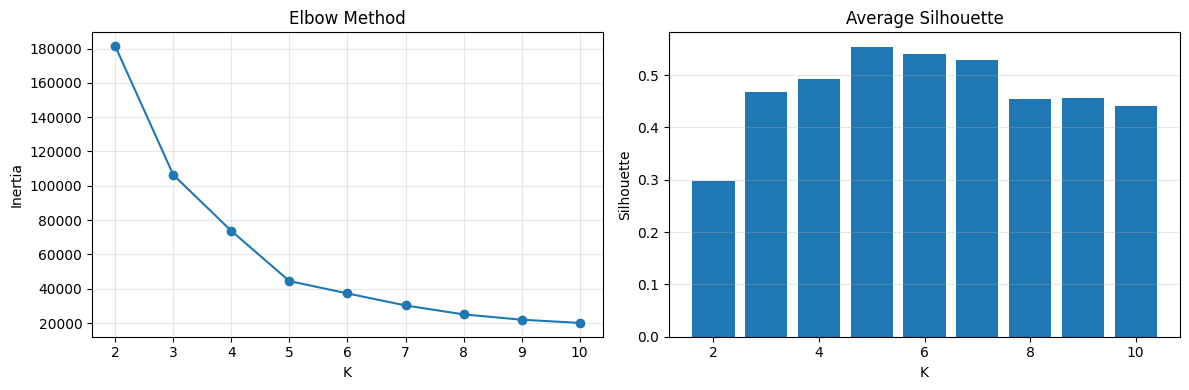

Highest average silhouette K = 5 with score = 0.5539
Elbow is the bend where inertia reduction starts slowing; inspect the curve rather than selecting the lowest inertia.


In [50]:
elbow_rows = []
models_by_k = {}
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels_k = model.fit_predict(X2)
    sil = silhouette_score(X2, labels_k)
    elbow_rows.append({"K":k, "Inertia":model.inertia_, "Silhouette":sil})
    models_by_k[k] = model
elbow_df = pd.DataFrame(elbow_rows)
display(elbow_df.round(3))
best_sil_k = int(elbow_df.loc[elbow_df["Silhouette"].idxmax(), "K"])
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(elbow_df.K, elbow_df.Inertia, marker="o"); ax[0].set(title="Elbow Method",xlabel="K",ylabel="Inertia"); ax[0].grid(alpha=.3)
ax[1].bar(elbow_df.K, elbow_df.Silhouette); ax[1].set(title="Average Silhouette",xlabel="K",ylabel="Silhouette"); ax[1].grid(axis="y",alpha=.3)
plt.tight_layout(); plt.show()
print("Highest average silhouette K =", best_sil_k, "with score =", round(elbow_df.loc[elbow_df.K==best_sil_k,"Silhouette"].iloc[0],4))
print("Elbow is the bend where inertia reduction starts slowing; inspect the curve rather than selecting the lowest inertia.")

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [51]:
k5_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = k5_model.labels_
sil_values = silhouette_samples(X2, labels5)
def silhouette_by_hand(X, labels, index):
    X = np.asarray(X, dtype=float); labels = np.asarray(labels)
    distances = np.sqrt(((X - X[index])**2).sum(axis=1))
    own = labels[index]
    same = np.where(labels == own)[0]
    same = same[same != index]
    a = distances[same].mean() if len(same) else 0.0
    other_means = [distances[labels == c].mean() for c in np.unique(labels) if c != own]
    b = min(other_means)
    s = (b-a)/max(a,b) if max(a,b)>0 else 0.0
    return a,b,s
a0,b0,s0 = silhouette_by_hand(X2, labels5, 0)
print(f"Customer 1 (row 0): a={a0:.5f}, b={b0:.5f}, hand s={s0:.5f}, sklearn s={sil_values[0]:.5f}")
cluster_sil = pd.DataFrame({"Cluster":labels5,"Silhouette":sil_values}).groupby("Cluster").Silhouette.agg(["count","mean","min"])
display(cluster_sil)
print("Customers with negative silhouette:", int((sil_values<0).sum()))
print("Negative silhouette means the customer may be closer on average to another cluster than to its assigned cluster.")

Customer 1 (row 0): a=24.64044, b=42.26527, hand s=0.41700, sklearn s=0.41700


,count,mean,min
Cluster,,,
0,81,0.597,0.115
1,39,0.509,0.225
2,22,0.599,0.051
3,35,0.504,-0.023
4,23,0.512,-0.009


Customers with negative silhouette: 2
Negative silhouette means the customer may be closer on average to another cluster than to its assigned cluster.


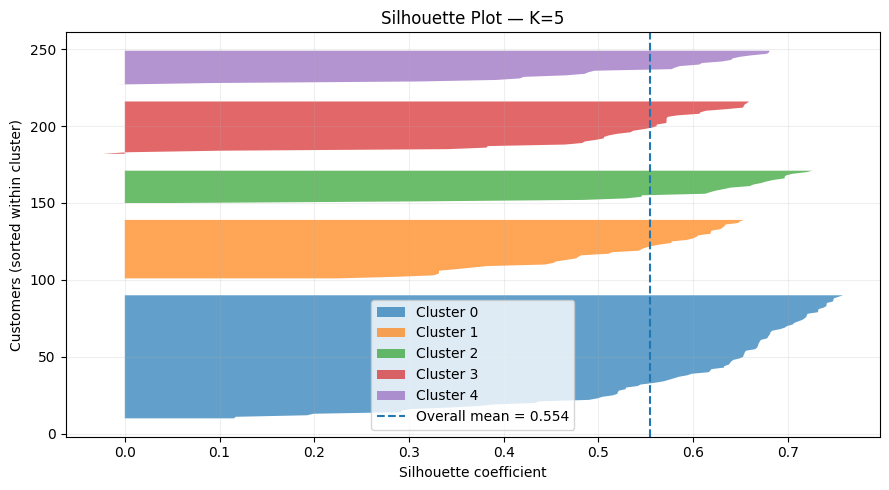

Interpretation: wider positive bands indicate better-separated customers; values near zero are boundary cases and negative values may be assigned poorly.


In [52]:
fig, ax = plt.subplots(figsize=(9,5))
y_lower = 10
for cluster in np.unique(labels5):
    vals = np.sort(sil_values[labels5 == cluster])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower,y_upper), 0, vals, alpha=.7, label=f"Cluster {cluster}")
    y_lower = y_upper + 10
ax.axvline(sil_values.mean(), linestyle="--", label=f"Overall mean = {sil_values.mean():.3f}")
ax.set(title="Silhouette Plot — K=5", xlabel="Silhouette coefficient", ylabel="Customers (sorted within cluster)")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()
print("Interpretation: wider positive bands indicate better-separated customers; values near zero are boundary cases and negative values may be assigned poorly.")

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [53]:
practice = np.array([1,3,5,7,11,13,15], dtype=float).reshape(-1,1)
p_labels,p_centers,p_inertia,p_iters = my_kmeans(practice, np.array([[1.],[11.]]))
print("Clusters:", {k: practice[p_labels==k].ravel().tolist() for k in range(2)})
print("Centroids:",p_centers.ravel(),"Inertia:",p_inertia,"Iterations:",p_iters)
p_sil = silhouette_samples(practice,p_labels)
for value in [1,7,11]:
    idx = int(np.where(practice.ravel()==value)[0][0])
    a,b,s = silhouette_by_hand(practice,p_labels,idx)
    print(f"Point {value}: a={a:.3f}, b={b:.3f}, hand s={s:.3f}, sklearn s={p_sil[idx]:.3f}")
print("The point with the lower silhouette is less well placed; compare both values above.")

Clusters: {0: [1.0, 3.0, 5.0, 7.0], 1: [11.0, 13.0, 15.0]}
Centroids: [ 4. 13.] Inertia: 28.0 Iterations: 3
Point 1: a=4.000, b=12.000, hand s=0.667, sklearn s=0.667
Point 7: a=4.000, b=6.000, hand s=0.333, sklearn s=0.333
Point 11: a=3.000, b=7.000, hand s=0.571, sklearn s=0.571
The point with the lower silhouette is less well placed; compare both values above.


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

**Answers:** According to the executive summary in my notebook, the best silhouette score suggests K = 5. The elbow method should also be checked using the inertia table and elbow plot to identify where the decrease in inertia becomes smaller.


(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

**Answer:** The exact silhouette of customer 1 is 0.225, weakest cluster average 0.051 and 2 customers have a negative value.

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

**Answer:** Point 7 is less well placed because its silhouette is lower.
- Point 1: a = 4, b = 12, silhouette = 0.667
- Point 7: a = 4, b = 6, silhouette = 0.333
Point 7 is closer to the other cluster than point 1, so its cluster assignment is less clearly separated.

(d) Why should we never choose K only by the lowest inertia?

**Answer:** Inertia always decreases when the number of clusters increases. If we choose K only by the lowest inertia, we may end up creating too many clusters. We should also consider silhouette score, the elbow plot, and the practical meaning of the groups.


## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


,Setting,Distinct inertia (1dp),Lowest,Highest,% reached best
0,"random, n_init=1",14,44448.455,91761.976,33.333
1,"k-means++, n_init=1",6,44448.455,66733.439,60.000
2,"k-means++, n_init=10",1,44448.455,44448.455,100.000


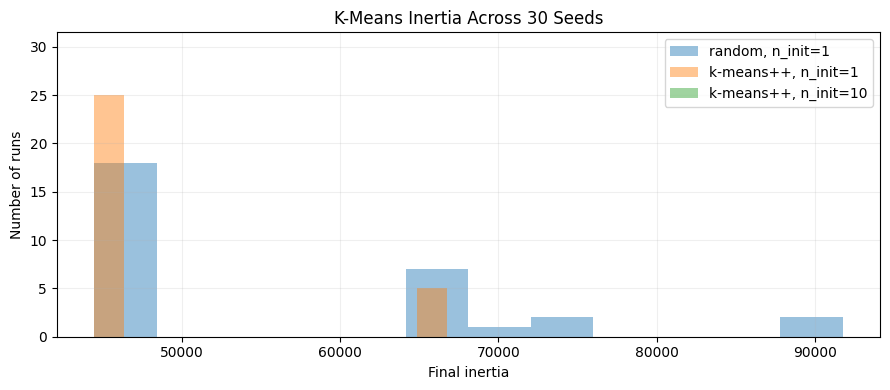

Different initial centroids can lead to different local minima. k-means++ spreads initial centres; n_init=10 tries multiple starts and keeps the lowest-inertia result.


In [54]:
runs = {"random, n_init=1":[], "k-means++, n_init=1":[], "k-means++, n_init=10":[]}
for seed in range(30):
    for setting, init, n_init in [
        ("random, n_init=1","random",1),
        ("k-means++, n_init=1","k-means++",1),
        ("k-means++, n_init=10","k-means++",10)]:
        m = KMeans(n_clusters=5, init=init, n_init=n_init, random_state=seed)
        m.fit(X2)
        runs[setting].append({"seed":seed,"inertia":m.inertia_,"model":m})
stability_rows=[]
for setting, records in runs.items():
    vals=np.array([r["inertia"] for r in records])
    best=vals.min()
    stability_rows.append({"Setting":setting,"Distinct inertia (1dp)":len(np.unique(np.round(vals,1))),
                           "Lowest":best,"Highest":vals.max(),
                           "% reached best":100*np.mean(np.isclose(vals,best,rtol=1e-7,atol=1e-7))})
stability_df=pd.DataFrame(stability_rows)
display(stability_df.round(3))
fig,ax=plt.subplots(figsize=(9,4))
for setting,records in runs.items():
    ax.hist([r["inertia"] for r in records],bins=12,alpha=.45,label=setting)
ax.set(title="K-Means Inertia Across 30 Seeds",xlabel="Final inertia",ylabel="Number of runs"); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout();plt.show()
print("Different initial centroids can lead to different local minima. k-means++ spreads initial centres; n_init=10 tries multiple starts and keeps the lowest-inertia result.")

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


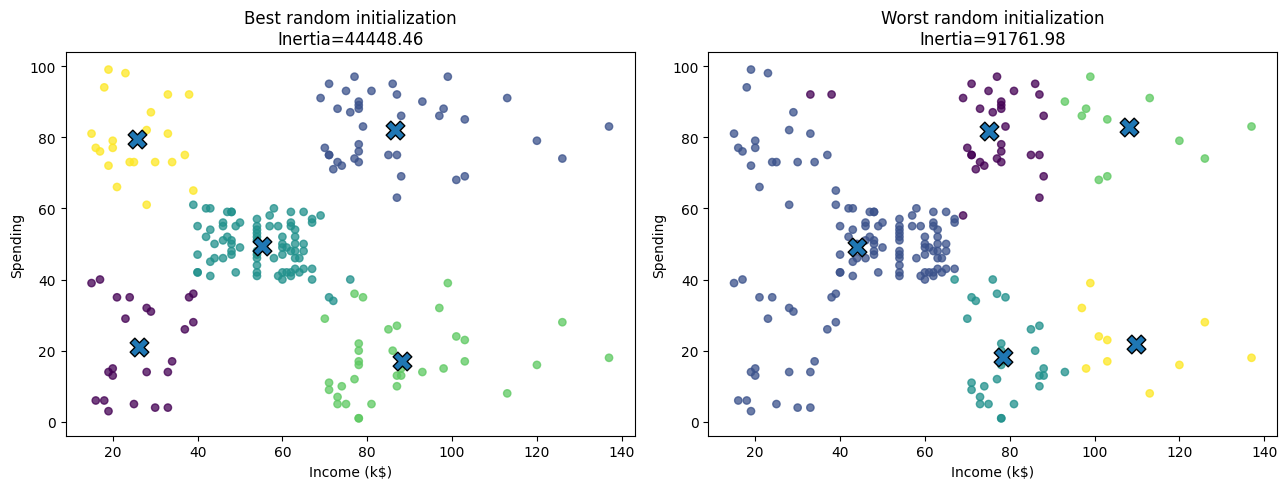

Best inertia: 44448.45544793369 | Worst inertia: 91761.97619211912
ARI best vs worst: 0.45525713010305063
ARI compares membership patterns and ignores arbitrary numeric cluster IDs.


In [55]:
random_runs=runs["random, n_init=1"]
best_record=min(random_runs,key=lambda r:r["inertia"])
worst_record=max(random_runs,key=lambda r:r["inertia"])
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,rec,title in [(axes[0],best_record,"Best random initialization"),(axes[1],worst_record,"Worst random initialization")]:
    m=rec["model"]
    ax.scatter(X2[:,0],X2[:,1],c=m.labels_,s=28,alpha=.75)
    ax.scatter(m.cluster_centers_[:,0],m.cluster_centers_[:,1],marker="X",s=180,edgecolor="black")
    ax.set(title=f"{title}\nInertia={m.inertia_:.2f}",xlabel="Income (k$)",ylabel="Spending")
plt.tight_layout();plt.show()
print("Best inertia:",best_record["inertia"],"| Worst inertia:",worst_record["inertia"])
print("ARI best vs worst:",adjusted_rand_score(best_record["model"].labels_,worst_record["model"].labels_))
print("ARI compares membership patterns and ignores arbitrary numeric cluster IDs.")

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

**Answer:** Random n_init is 1

(b) Why can the same data and the same K give different answers?

**Answer:** K-Means starts with randomly selected initial centroids. Different starting points can produce different cluster assignments and final centroids. This can lead the algorithm to different local minima, even when the dataset and K remain the same.

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

**Answer:** K-means++ selects better-spaced initial centroids, reducing the chance of poor initialization. The n_init parameter runs K-Means multiple times with different initializations and selects the solution with the lowest inertia.

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?

**Answer:** Cluster numbers are arbitrary. For example, cluster 0 in one model may represent the same group as cluster 3 in another model. ARI compares the actual grouping structure rather than the cluster numbers. An ARI of 1 means identical groupings.

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.


(c) Name two ways to deal with outliers and one risk of simply deleting them.



## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why?



## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


**Executive Summary** (6-8 lines)


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?

